# 01 Velocity model

Background Vp and Vs model for Rotokawa, built from the known geology.

Output: `data/velocity_model.npz`

In [5]:
# --- Imports ---
import json

import numpy as np
import matplotlib.pyplot as plt

import geopandas as gpd
from shapely.geometry import box

In [13]:
# --- Site ---
site = json.load(open("../data/site.json"))
DRILL = (site["drill_site"]["lon"], site["drill_site"]["lat"])
ELEV = site["elevation_km"]
KY = 111.32 # km per degree latitude
KX = KY * np.cos(np.radians(DRILL[1])) # km per degree longitude here


def km(lon, lat):
    """lon, lat -> km east and north of the drill site."""
    return (np.asarray(lon) - DRILL[0]) * KX, (np.asarray(lat) - DRILL[1]) * KY


# --- Grid ---
GRID_HALF, DXY = 16.0, 0.25
ZMAX, DZ = 20.0, 0.1 

x = np.arange(-GRID_HALF, GRID_HALF + 1e-9, DXY)
y = np.arange(-GRID_HALF, GRID_HALF + 1e-9, DXY)
z = np.arange(0, ZMAX + 1e-9, DZ)
X, Y = np.meshgrid(x, y, indexing="ij")

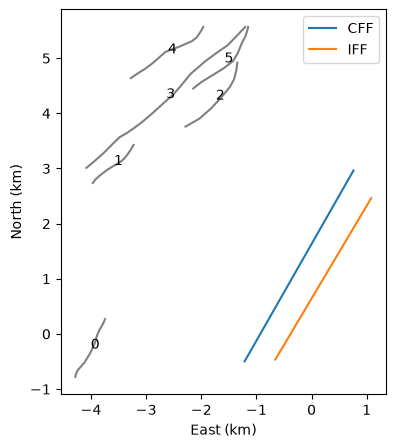

In [14]:
# --- Fault Zone strands (GNS Active Faults Database) ---
af = gpd.read_file("../data/NZAFD_250K_Nov_2026_WGS84.shp").to_crs(epsg=4326)

bbox = box(DRILL[0] - 0.05, DRILL[1] - 0.05, DRILL[0] + 0.05, DRILL[1] + 0.05)
ara = af[af["name"].str.contains("Aratiatia", case=False, na=False)]
ara = gpd.clip(ara, bbox).explode(index_parts=False).reset_index(drop=True)


def endpoints(geom):
    pts = sorted([geom.coords[0], geom.coords[-1]], key=lambda p: p[1])
    return [(round(lon, 4), round(lat, 4)) for lon, lat in pts]


CFF = [(176.1874, -38.6350), (176.2101, -38.6039)]    # Wallis et al. 2013
IFF = [(176.1938, -38.6347), (176.2138, -38.6084)]    # Wallis et al. 2013

with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(5, 5))
    for i, g in enumerate(ara.geometry):
        ax.plot(*km(*g.xy), color="grey")
        ax.annotate(str(i), km(*g.centroid.coords[0]))
    for name, tr in [("CFF", CFF), ("IFF", IFF)]:
        ax.plot(*km(*zip(*tr)), label=name)
    ax.set(aspect="equal", xlabel="East (km)", ylabel="North (km)")
    ax.legend()
    plt.show()

In [17]:
# --- Faults, NW to SE: trace (lon, lat), dip, dip direction ---
i6, i7 = 0, 1
FAULTS = {
    "AF6": dict(trace=endpoints(ara.geometry[i6]), dip=80, dip_dir="SE"),   # NZAFD trace; dip estimated
    "AF7": dict(trace=endpoints(ara.geometry[i7]), dip=80, dip_dir="SE"),   # NZAFD trace; dip estimated
    "CFF": dict(trace=CFF, dip=86, dip_dir="NW"), # dip estimated
    "IFF": dict(trace=IFF, dip=82, dip_dir="NW"), # dip estimated
}

# dips: no published values; steep dips consistent with >60 deg fractures in wells (McNamara et al. 2017)
STRIKE = 30 # mean fault strike, degrees (Mroczek et al. 2020, after Wallis et al. 2013)
FAULT_EXTEND, FAULT_TAPER = 4.0, 2.0   # faults run 4 km past their mapped ends, then fade over 2 km. modelling choice

# --- Layer tops in each fault block, NW to SE (km below ground) ---
# blocks: W of AF6 | AF6-AF7 | AF7-CFF (graben) | CFF-IFF | E of IFF
GW_TOP = [2.20, 2.50, 2.80, 2.00, 1.80]     # Calibugan et al. 2022 cross-section, read approx., +0.35 km datum
AN_TOP = [1.05, 1.10, 1.15, 0.95, 0.90]     # Rotokawa Andesite top at ~1 km (Heise et al. 2008); offsets schematic

# --- Shallow layers (km below ground) ---
COVER = 0.1                            # surface cover, 0-100 m (Milicich et al. 2020)
CLAY_MIN, CLAY_MAX = 0.3, 0.65         # clay-rich base: ~300 m over the centre, deeper on flanks (Heise et al. 2008)
UPFLOW = (-0.5, 0.0)                   # where the clay is thinnest (km from drill site). estimate

# --- Velocities: 1D model of Sewell et al. 2017 (Mroczek et al. 2020, Table 2) ---
V1D_Z = np.array([0.0, 0.2, 1.0, 1.5, 2.0, 3.0, 5.0, 10.0, 20.0])          # depth (km)
V1D_VP = np.array([1.90, 2.60, 3.50, 3.60, 3.90, 4.90, 5.40, 5.81, 6.90])  # km/s
V1D_VS = np.array([1.20, 1.50, 2.00, 2.20, 2.40, 3.00, 3.20, 3.32, 3.94])  # km/s
V1D_SHIFT = 0.0

UNIT_Z = {"cover": (0.0, 0.0),\
          "clay_rich": (0.2, 0.2),
          "volcanics": (0.2, 1.0),
          "andesite": (1.5, 2.0)}

# greywacke (Kaweka Terrane)
GW_Z = np.array([1.6, 3.0, 5.0, 10.0, 20.0])

In [19]:
# --- Fault planes ---
u = np.array([np.sin(np.radians(STRIKE)), np.cos(np.radians(STRIKE))])   # along-strike direction
for f in FAULTS.values():
    p = np.column_stack(km(*np.array(f["trace"]).T))                    # trace in km, south end first
    d = (p[1] - p[0]) / np.linalg.norm(p[1] - p[0])                     # along the trace
    f["p0"], f["n"] = p[0], np.array([d[1], -d[0]])                     # a point, and SE-pointing normal
    f["sign"] = 1 if f["dip_dir"] == "SE" else -1
    f["along"] = p @ u
a_min = min(f["along"].min() for f in FAULTS.values()) - FAULT_EXTEND
a_max = max(f["along"].max() for f in FAULTS.values()) + FAULT_EXTEND


def across(f, x, y, depth):
    shift = f["sign"] * depth / np.tan(np.radians(f["dip"]))
    return (x - f["p0"][0]) * f["n"][0] + (y - f["p0"][1]) * f["n"][1] - shift


def taper(x, y):
    a = x * u[0] + y * u[1]
    return np.clip(1 - np.maximum(a_min - a, a - a_max) / FAULT_TAPER, 0, 1)

In [20]:
# --- Clay-rich unit base: thinnest over the upflow ---
r = np.hypot(X - UPFLOW[0], Y - UPFLOW[1])
clay_base = np.clip(CLAY_MIN + (CLAY_MAX - CLAY_MIN) * (r / 5) ** 2, CLAY_MIN, CLAY_MAX)


# --- Greywacke and andesite tops: block depths, stepping at each fault ---
def stepped(tops, depth):
    """Depth map that starts at the NW block value and changes by each block difference across each fault."""
    out = np.full(X.shape, tops[0])
    for f, dz in zip(FAULTS.values(), np.diff(tops)):
        out += dz * taper(X, Y) * (across(f, X, Y, depth) > 0)
    return out


gw_top = stepped(GW_TOP, np.mean(GW_TOP))
an_top = np.minimum(stepped(AN_TOP, np.mean(AN_TOP)), gw_top - 0.2)   # andesite at least 0.2 km above greywacke

In [21]:
# --- 1D model on depth axis ---
v1p = lambda d: np.interp(d - V1D_SHIFT, V1D_Z, V1D_VP)
v1s = lambda d: np.interp(d - V1D_SHIFT, V1D_Z, V1D_VS)

# --- Greywacke velocities: 1D below 3 km, extended upward along the 3-5 km gradient ---
gp, gs = (v1p(5.0) - v1p(3.0)) / 2, (v1s(5.0) - v1s(3.0)) / 2          # km/s per km
GW_VP = np.where(GW_Z < 3, v1p(3.0) - gp * (3 - GW_Z), v1p(GW_Z))
GW_VS = np.where(GW_Z < 3, v1s(3.0) - gs * (3 - GW_Z), v1s(GW_Z))

# --- Greywacke everywhere, varying with depth ---
Z3 = z[None, None, :]
ones = np.ones(X.shape)[..., None]
vp = np.interp(Z3, GW_Z, GW_VP) * ones
vs = np.interp(Z3, GW_Z, GW_VS) * ones

# --- Units above the greywacke, painted over it ---
TOP = {"cover": 0 * clay_base, "clay_rich": COVER + 0 * clay_base, "volcanics": clay_base, "andesite": an_top}
BASE = {"cover": COVER + 0 * clay_base, "clay_rich": clay_base, "volcanics": an_top, "andesite": gw_top}

for name, (d0, d1) in UNIT_Z.items():
    t, b = TOP[name][..., None], BASE[name][..., None]
    inside = (Z3 >= t) & (Z3 < b)
    frac = np.clip((Z3 - t) / np.maximum(b - t, 1e-6), 0, 1)
    vp = np.where(inside, v1p(d0) + frac * (v1p(d1) - v1p(d0)), vp)
    vs = np.where(inside, v1s(d0) + frac * (v1s(d1) - v1s(d0)), vs)

In [22]:
# --- Save ---
np.savez_compressed("../data/velocity_model.npz", x=x, y=y, z=z, vp=vp, vs=vs,
                    clay_base=clay_base, an_top=an_top, gw_top=gw_top)
print("vp", vp.shape, f"{vp.min():.2f}-{vp.max():.2f} km/s")

vp (129, 129, 201) 1.90-6.90 km/s


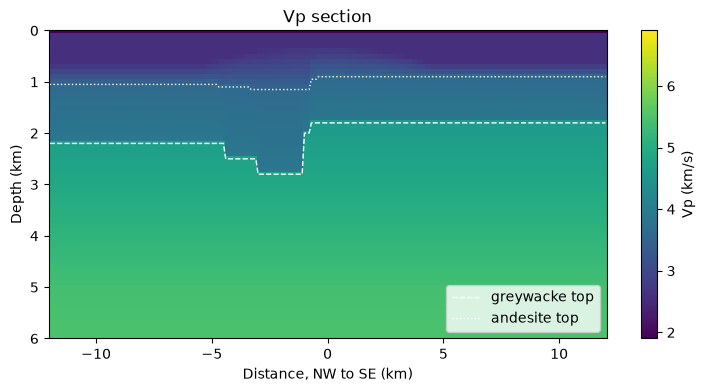

In [23]:
# --- Vp section through the drill site, across the faults ---
AZ = 120
s = np.linspace(-12, 12, 241)
ix = np.clip(np.round((s * np.sin(np.radians(AZ)) + GRID_HALF) / DXY).astype(int), 0, len(x) - 1)
iy = np.clip(np.round((s * np.cos(np.radians(AZ)) + GRID_HALF) / DXY).astype(int), 0, len(y) - 1)

with plt.style.context("default"):
    fig, ax = plt.subplots(figsize=(9, 4))
    pc = ax.pcolormesh(s, z, vp[ix, iy, :].T, cmap="viridis", shading="auto")
    ax.plot(s, gw_top[ix, iy], "w--", lw=1, label="greywacke top")
    ax.plot(s, an_top[ix, iy], "w:", lw=1, label="andesite top")
    ax.set(ylim=(6, 0), xlabel="Distance, NW to SE (km)", ylabel="Depth (km)", title="Vp section")
    ax.legend(loc="lower right")
    fig.colorbar(pc, label="Vp (km/s)")
    plt.show()